# Phase 7.2 - Next Token Prediction (Transformer)

Objetivo:
- Usar el vocabulario completo de tokens de `phase6 v6.2`.
- Predecir el **siguiente token probable** desde una secuencia previa.
- Comparar contra baseline secuencial (`Markov 1er orden`).

Nota:
- `top-k all` incluye pasos triviales donde el token se mantiene.
- `top-k change` evalua solo cuando el token realmente cambia (escenario mas dificil y util).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('.')

import importlib.util
script_path = ROOT / 'phases/phase07_online_detector/run_phase7_next_token_transformer_v2.py'
spec = importlib.util.spec_from_file_location('run_phase7_next_token_transformer_v2', script_path)
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
summary, history_df, pred_base_df, pred_model_df = mod.main()

OUT_DIR = ROOT / 'phases/phase07_online_detector/output_next_token_GBPUSD_v2'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_next_token_summary_v2.json'
HISTORY_CSV = OUT_DIR / 'GBPUSD_next_token_train_history_v2.csv'
BASE_CSV = OUT_DIR / 'GBPUSD_next_token_test_predictions_baseline_v2.csv'
MODEL_CSV = OUT_DIR / 'GBPUSD_next_token_test_predictions_transformer_v2.csv'
SAMPLES_CSV = OUT_DIR / 'GBPUSD_next_token_samples_v2.csv'

summary = json.loads(SUMMARY_JSON.read_text())
history = pd.read_csv(HISTORY_CSV)
preds_base = pd.read_csv(BASE_CSV)
preds_model = pd.read_csv(MODEL_CSV)
samples = pd.read_csv(SAMPLES_CSV)

print('summary ->', SUMMARY_JSON)
print('history ->', HISTORY_CSV)
print('baseline preds ->', BASE_CSV)
print('transformer preds ->', MODEL_CSV)

Saved summary: ./phases/phase07_online_detector/output_next_token_GBPUSD_v2/GBPUSD_next_token_summary_v2.json
Baseline test: {'top1_all': 0.9152542372881356, 'top3_all': 0.9378531073446328, 'top5_all': 0.9717514124293786, 'n_change': 15, 'change_ratio': 0.0847457627118644, 'top1_change': 0.0, 'top3_change': 0.26666666666666666, 'top5_change': 0.6666666666666666}
Transformer test: {'loss': 0.5501268953084946, 'top1_all': 0.9152542372881356, 'top3_all': 0.9548022598870056, 'top5_all': 0.9717514124293786, 'n_change': 15, 'change_ratio': 0.0847457627118644, 'top1_change': 0.0, 'top3_change': 0.4666666666666667, 'top5_change': 0.6666666666666666}
summary -> ./phases/phase07_online_detector/output_next_token_GBPUSD_v2/GBPUSD_next_token_summary_v2.json
history -> ./phases/phase07_online_detector/output_next_token_GBPUSD_v2/GBPUSD_next_token_train_history_v2.csv
baseline preds -> ./phases/phase07_online_detector/output_next_token_GBPUSD_v2/GBPUSD_next_token_test_predictions_baseline_v2.csv
tra

In [2]:
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

print('N vocab:', summary['n_vocab'])
print('Samples:', summary['n_samples'])
print('\nBaseline metrics:')
print(summary['baseline_markov1_test'])
print('\nTransformer metrics:')
print(summary['transformer_test'])

N vocab: 12
Samples: {'train': 1036, 'val': 177, 'test': 177}

Baseline metrics:
{'top1_all': 0.9152542372881356, 'top3_all': 0.9378531073446328, 'top5_all': 0.9717514124293786, 'n_change': 15, 'change_ratio': 0.0847457627118644, 'top1_change': 0.0, 'top3_change': 0.26666666666666666, 'top5_change': 0.6666666666666666}

Transformer metrics:
{'loss': 0.5501268953084946, 'top1_all': 0.9152542372881356, 'top3_all': 0.9548022598870056, 'top5_all': 0.9717514124293786, 'n_change': 15, 'change_ratio': 0.0847457627118644, 'top1_change': 0.0, 'top3_change': 0.4666666666666667, 'top5_change': 0.6666666666666666}


,model,top1_all,top3_all,top5_all,top1_change,top3_change,top5_change
0,baseline_markov1,0.915254,0.937853,0.971751,0.0,0.266667,0.666667
1,transformer_v2,0.915254,0.954802,0.971751,0.0,0.466667,0.666667


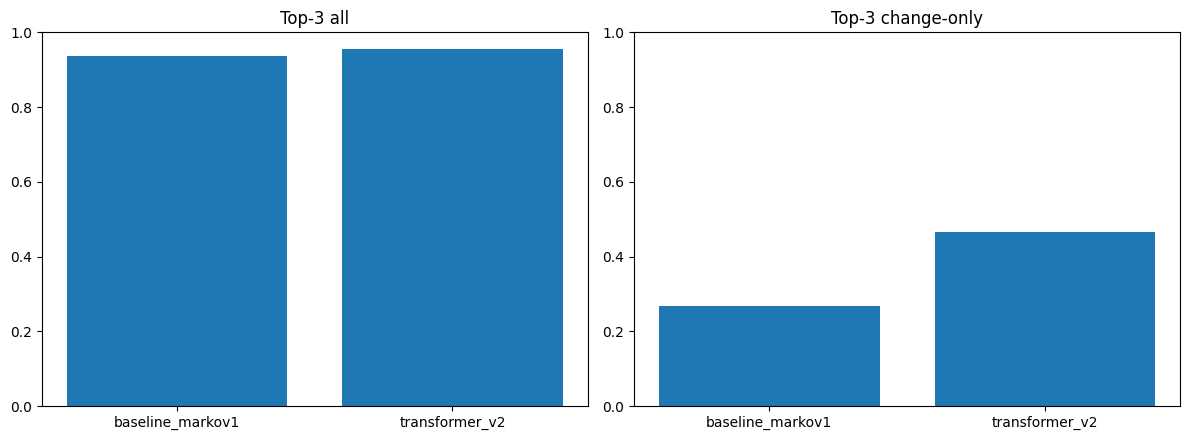

In [3]:
# Comparativo top-k
b = summary['baseline_markov1_test']
m = summary['transformer_test']

cmp = pd.DataFrame([
    {'model': 'baseline_markov1', 'top1_all': b['top1_all'], 'top3_all': b['top3_all'], 'top5_all': b['top5_all'], 'top1_change': b['top1_change'], 'top3_change': b['top3_change'], 'top5_change': b['top5_change']},
    {'model': 'transformer_v2',   'top1_all': m['top1_all'], 'top3_all': m['top3_all'], 'top5_all': m['top5_all'], 'top1_change': m['top1_change'], 'top3_change': m['top3_change'], 'top5_change': m['top5_change']},
])

display(cmp)

fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
axes[0].bar(cmp['model'], cmp['top3_all'])
axes[0].set_title('Top-3 all')
axes[0].set_ylim(0,1)

axes[1].bar(cmp['model'], cmp['top3_change'])
axes[1].set_title('Top-3 change-only')
axes[1].set_ylim(0,1)

plt.tight_layout()
plt.show()

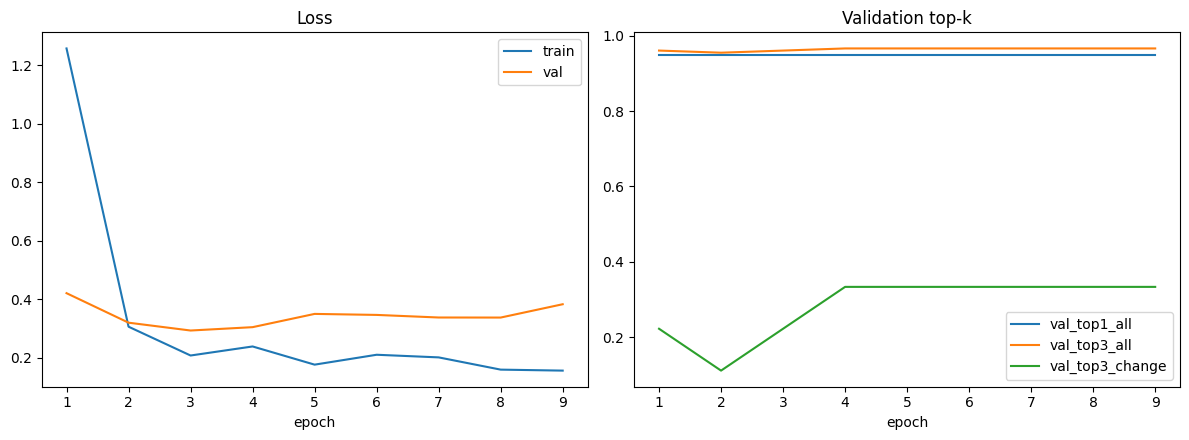

,epoch,lr,train_loss,val_loss,train_top1_all,train_top3_all,train_top5_all,train_top3_change,val_top1_all,val_top3_all,val_top5_all,val_top3_change
0,1,0.00100,1.256894,0.420018,0.658301,0.768340,0.839768,0.775938,0.949153,0.960452,0.966102,0.222222
1,2,0.00100,0.305368,0.319111,0.957529,0.973938,0.986486,0.974157,0.949153,0.954802,0.966102,0.111111
2,3,0.00100,0.206864,0.292307,0.957529,0.980695,0.987452,0.978818,0.949153,0.960452,0.971751,0.222222
3,4,0.00100,0.237808,0.303791,0.956564,0.987452,0.995174,0.986441,0.949153,0.966102,0.971751,0.333333
4,5,0.00100,0.175607,0.349124,0.944015,0.990347,0.996139,0.991081,0.949153,0.966102,0.977401,0.333333
5,6,0.00050,0.209439,0.345677,0.957529,0.990347,0.998069,0.991180,0.949153,0.966102,0.971751,0.333333
6,7,0.00050,0.200450,0.336826,0.950772,0.990347,1.000000,0.990022,0.949153,0.966102,0.971751,0.333333
7,8,0.00050,0.158579,0.336628,0.955598,0.994208,1.000000,0.993304,0.949153,0.966102,0.971751,0.333333
8,9,0.00025,0.155210,0.382198,0.956564,0.995174,1.000000,0.994512,0.949153,0.966102,0.977401,0.333333


In [4]:
# Curva de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))

axes[0].plot(history['epoch'], history['train_loss'], label='train')
axes[0].plot(history['epoch'], history['val_loss'], label='val')
axes[0].set_title('Loss')
axes[0].set_xlabel('epoch')
axes[0].legend()

axes[1].plot(history['epoch'], history['val_top1_all'], label='val_top1_all')
axes[1].plot(history['epoch'], history['val_top3_all'], label='val_top3_all')
axes[1].plot(history['epoch'], history['val_top3_change'], label='val_top3_change')
axes[1].set_title('Validation top-k')
axes[1].set_xlabel('epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

display(history)

In [5]:
# Ejemplos: casos de cambio de token en test
preds_model['is_correct_top1'] = (preds_model['pred_token_id_top1'] == preds_model['target_token_id']).astype(int)
changes = preds_model[preds_model['is_change'] == 1].copy()

print('N cambios test =', len(changes))
display(changes[['end_ts','last_token','target_token','pred_token_top1','prob_top1','pred_token_top2','prob_top2','pred_token_top3','prob_top3','is_correct_top1']].head(30))

N cambios test = 15


,end_ts,last_token,target_token,pred_token_top1,prob_top1,pred_token_top2,prob_top2,pred_token_top3,prob_top3,is_correct_top1
10,2022-08-04 01:00:00,w07,w02,w07,0.946584,w00,0.021793,w02,0.007577,0
29,2022-10-06 05:00:00,w02,w11,w02,0.945375,w03,0.021585,w05,0.006766,0
36,2022-10-20 04:00:00,w11,w03,w11,0.938380,w03,0.013689,w02,0.013141,0
40,2022-11-01 03:00:00,w03,w11,w03,0.947524,w02,0.012371,w05,0.008302,0
41,2022-11-02 08:00:00,w11,w07,w11,0.926794,w03,0.022043,w02,0.014695,0
43,2022-11-04 01:00:00,w07,w03,w07,0.944835,w00,0.020682,w02,0.010976,0
59,2022-12-14 21:00:00,w03,w07,w03,0.959559,w02,0.009268,w07,0.006076,0
63,2023-01-05 02:00:00,w07,w03,w07,0.922827,w00,0.027125,w03,0.016347,0
66,2023-01-15 21:00:00,w03,w07,w03,0.958850,w02,0.009307,w07,0.006208,0
70,2023-02-07 06:00:00,w07,w03,w07,0.910777,w00,0.033808,w03,0.018821,0


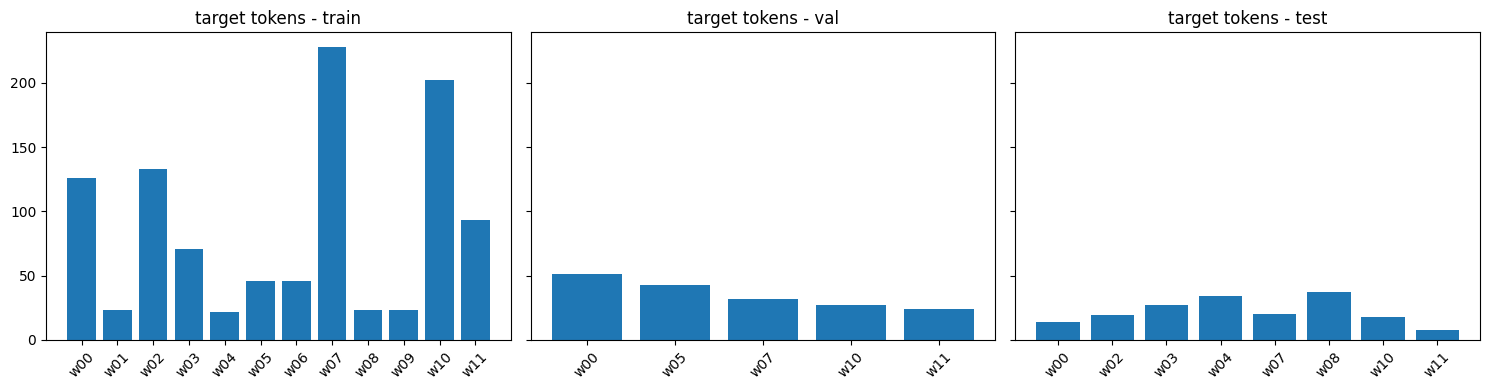

In [6]:
# Distribucion de targets en muestras (train/val/test)
fig, axes = plt.subplots(1, 3, figsize=(15,4), sharey=True)
for ax, sp in zip(axes, ['train','val','test']):
    s = samples[samples['split']==sp]['target_token'].value_counts().sort_index()
    ax.bar(s.index, s.values)
    ax.set_title(f'target tokens - {sp}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()